# Text Classifiers using LLMs

## Tutorial 3 (Week 5)

Welcome to the last NLP1 tutorial. During the last two weeks, we focused on learning about different text classifiers: ones that treat documents as a collection of words, represented by pre-trained embeddings, and others that incorporate word order (i.e. LSTMs). In this tutorial, we move to more modern architectures: transformer-based language models, and learn how to adapt them with efficient fine-tuning techniques.

In [1]:
# Import relevant packages
from datasets import load_dataset
import os
import json
import pickle

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
from utils.eval_analysis_utils import evaluate_predictions

In [4]:
import sys
from pathlib import Path
root = Path.cwd().parent
sys.path.insert(0, str(root))

import part1

### 3.0 Preparing data

In [5]:
#Loading our training corpus
dataset = load_dataset("fancyzhx/ag_news") 

my_seeds = [0] # [0, 3, 5] # add more seeds here for multiple runs of cross validation, eg. [0, 3, 5]  
num_folds = 5  # more makes each cross validation run more statistically informative, but it can get slow
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        part1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(dataset["train"]["text"], dataset["train"]["label"])), 
            k=num_folds,
            seed=seed
        )
    )

In [6]:
#Save cross validation sets
os.makedirs("data", exist_ok=True)

with open("data/cross_validation_sets.pkl", "wb") as f:
    pickle.dump(my_cross_validation_sets, f)


### 3.1 Adapting Language models

We are now working with larger models in terms of parameters that were pre-trained with the language modeling task (i.e. predicting the next token), on a huge corpora. Then models are fine-tuned to follow instructions and/or tuned with some preference optimisation procedure, so that their generations align better with text preferred by humans. 

Such models are found to have great capabilities in a broad range of tasks, generalising well to unseen instances. They can be used off-the-shelf, without further training for a range of tasks, by providing instructions and the instance for which we seek to make a prediction in the prompt. We call this *zero-shot prompting*, and it is the first technique we will be expriementing with in this tutorial.

#### 3.1.1 Generating with the model (0-shot)

As we will need to submit job scripts on a GPU instance of Snellius to load an LLM and sample generations from it, a `utils/generate.py` script was created for this purpose and you will find it in the supplementary material of the week. Inspect its `Generation` class, and make sure you understand the code. You can generate the greedy response by calling a previously created `Generation` object, with the `generate_greedy` method, and sample a response with the `generate_samples` method.

These can then be submitted to a Snellius GPU instance, via the `generate-0-shot.sh` file, where you can set various hyperparameters of the generation script. To submit to Snellius run this in the login node's terminal:
```ruby
sbatch /nlp1/part3/generate-0-shot.sh
```

We currently support 2 models, `qwen-0.5b-instruct` and `llama-3b-instruct`. We will be using the smaller of the two for the purposes of this tutorial, due to its conveniently smaller size, but you can experiment with the other one and compare results for your last project. 

Then, we can evaluate the quality of the predictions:

In [7]:
#Get all files in the predictions directory
model_name = "qwen-0.5b-instruct"
instruction_type = "0-shot"
output_path = "/home/eilia/nlp1/part3/predictions"

results_0_shot = evaluate_predictions(output_path, model_name, instruction_type, print_results=False)

/home/eilia/.local/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


#### 3.1.2 Generating with the model (few-shot)

Model performance is not very high! A way that oftentimes improves upon the 0-shot baseline is few-shot prompting. That means that instead of simply providing the model with the task instructions and an instance that we want to make a prediction for, we also add a few examples/demonstrations of inputs and the desired outputs in the prompt. 

In order to submit the job that generates predictions with few-shot prompting, use:
```ruby
sbatch /home/eilia/nlp1/part3/generate-few-shot.sh
```

Now we can evauate the quality of the predictions obtained with few-shot prompting:

In [8]:
#Get all files in the predictions directory
model_name = "qwen-0.5b-instruct"
instruction_type = "few-shot"
output_path = "/home/eilia/nlp1/part3/predictions"

results_few_shot = evaluate_predictions(output_path, model_name, instruction_type, print_results=False)

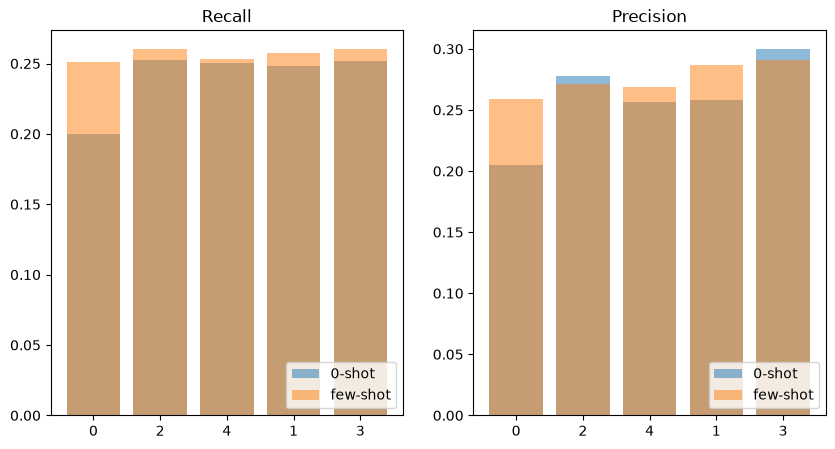

In [9]:
#Plot results
import matplotlib.pyplot as plt

#2 plots side by side
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[1].bar(results_0_shot.keys(), [x["precision"] for x in results_0_shot.values()], label="0-shot", alpha=0.5)
axs[1].bar(results_few_shot.keys(), [x["precision"] for x in results_few_shot.values()], label="few-shot", alpha=0.5)
axs[1].legend(loc="lower right")
axs[1].set_title("Precision")
axs[0].bar(results_0_shot.keys(), [x["recall"] for x in results_0_shot.values()], label="0-shot", alpha=0.5)
axs[0].bar(results_few_shot.keys(), [x["recall"] for x in results_few_shot.values()], label="few-shot", alpha=0.5)
axs[0].legend(loc="lower right")
axs[0].set_title("Recall")
plt.show()

We have only minimally improved the performance. To observe better improvements, we adapt our LLM for the specific task. We are working with a very small LLM, so their off-the-shelf performance for any task may not always be very high.

#### 3.1.3 Fine tuning the model

As modern LLMs are very large, full fine-tuning of LLMs might be infeasible. *Efficient fine-tuning* offers a promising  refers to adapting a language model to a specific NLP task without updating all of its parameters, which reduces computational cost, memory use, and training time. 

*LoRA (Low-Rank Adaptation)* is a popular parameter-efficient fine-tuning method that freezes the original model weights and learns small, low-rank matrices that are added to selected layers, typically the attention layers. This means only a small fraction of the model’s parameters are trained while still allowing the model to adapt effectively to a new task.

For a deeper undestanding: [LoRA: Low-Rank Adaptation of Large Language Models](https://arxiv.org/abs/2106.09685)

Similar to before, we will need to submit a script on a GPU instance of Snellius to fine-tune the LLM: see `utils/fine_tuning.py` in the supplementary material of the week. To run the script, we need to submit a job script:

```ruby
sbatch part3/fine-tuning.sh
```

Go through the script and ensure you understand it. 

To assess the performance of the newly trained model on our task, we need to generate the predictions of the fine-tuned model, before assessing their quality. Our `Generation` class in `generate.py` can load a model and tokenizer based on a LoRA fine-tuned model, given argument `adapter_path` that indicates the path at which we have saved the model during fine-tuning. To do that, submit the following job script:
```ruby
sbatch /home/eilia/nlp1/part3/generate-ft-0-shot.sh
```

Then we can load the resulting predictions file and obtain the accuracy:

In [11]:
#Get all files in the predictions directory
model_name = "qwen-0.5b-instruct-ft-lora"
instruction_type = "0-shot"
output_path = "/home/eilia/nlp1/part3/predictions"

results = evaluate_predictions(output_path, model_name, instruction_type, print_results=True)

Fold 1:
Accuracy: 0.91775
Precision: 0.9205147804070454
Recall: 0.9170406268021911
F1: 0.9173693845343025
--------------------------------
Fold 2:
Accuracy: 0.9220833333333334
Precision: 0.9230646784547119
Recall: 0.9219963285581234
F1: 0.9219012199768529
--------------------------------
Fold 0:
Accuracy: 0.9177083333333333
Precision: 0.91901628996969
Recall: 0.9179095903555459
F1: 0.9176924447939558
--------------------------------
Fold 4:
Accuracy: 0.916875
Precision: 0.9189301743383941
Recall: 0.9170368901593238
F1: 0.9170219116060291
--------------------------------
Fold 3:
Accuracy: 0.9165833333333333
Precision: 0.9177095203326557
Recall: 0.9169173472424103
F1: 0.9165447757576165
--------------------------------


### 3.2 Robustness analysis

#### 3.2.1 Out-of-Distribution settings

We have assessed the performance of our models on test sets that are distributed in a manner similar to the training and validation sets. However, we can now assess how the classification abilities of our candidate models generalise to text that does not come from the same distribution as the train and validation sets. 

We need a benchmark that targets the same classification task (including the same output space, i.e., identical classification labels). BBC news is one such dataset ([Hugging face ](https://huggingface.co/datasets/SetFit/bbc-news)|[ original paper](https://derekgreene.com/papers/greene06icml.pdf)) of topic classification news articles (1225 in training set and 1000 in the test set). 

In [28]:
#Loading our OOD test set
ood_dataset = load_dataset("SetFit/bbc-news") 
ood_train = ood_dataset["train"]
ood_test = ood_dataset["test"]

Here is an example of a news article from this dataset:

In [29]:
ood_test[0]

{'text': 'carry on star patsy rowlands dies actress patsy rowlands  known to millions for her roles in the carry on films  has died at the age of 71.  rowlands starred in nine of the popular carry on films  alongside fellow regulars sid james  kenneth williams and barbara windsor. she also carved out a successful television career  appearing for many years in itv s well-loved comedy bless this house. rowlands died in hove on saturday morning  her agent said.  born in january 1934  rowlands won a scholarship to the guildhall school of speech and drama scholarship when she was just 15.  after spending several years at the players theatre in london  she made her film debut in 1963 in tom jones  directed by tony richardson. she made her first carry on film in 1969 where she appeared in carry on again doctor. rowlands played the hard-done-by wife or the put-upon employee as a regular carry on star. she also appeared in carry on at your convenience  carry on matron and carry on loving  as we

In [30]:
#All possible classification labels
corpus_train_ood = [x["text"] for x in ood_train]
corpus_test_ood = [x["text"] for x in ood_test]

labels_train_ood = [x["label_text"] for x in ood_train]
labels_test_ood = [x["label_text"] for x in ood_test]
set(labels_test_ood)

{'business', 'entertainment', 'politics', 'sport', 'tech'}

In our original text classification datatset's classes: 

`{0: "World", 1: "Sports", 2: "Business", 3: "Science/Technology"}`. 

We have an almost 1-1 correspondence between topic classes, with entertainment falling outside the scope of classes we have learnt to classify for. We have to remove instances associated to that class, and map to the original labels:

`{0: "politics", 1: "sport", 2: "business", 3: "tech"}`. 

In [31]:
mapping = {"politics": 0, "sport": 1, "business": 2, "tech": 3, "entertainment": -1}

labels_test_ood = [mapping[x] for x in labels_test_ood]
pairs_test_ood = list(zip(corpus_test_ood, labels_test_ood))
filtered_pairs_test = [x for x in pairs_test_ood if x[1] != -1] # Remove instances associated to the entertainment class

labels_train_ood = [mapping[x] for x in labels_train_ood]
pairs_train_ood = list(zip(corpus_train_ood, labels_train_ood))
filtered_pairs_train = [x for x in pairs_train_ood if x[1] != -1] # Remove instances associated to the entertainment class

print(f"Number of instances in the OOD training set: {len(ood_train)}")
print(f"Number of instances in the OOD training set after removing the entertainment class: {len(filtered_pairs_train)}")

print(f"Number of instances in the OOD test set: {len(ood_test)}")
print(f"Number of instances in the OOD test set after removing the entertainment class: {len(filtered_pairs_test)}")

Number of instances in the OOD training set: 1225
Number of instances in the OOD training set after removing the entertainment class: 1015
Number of instances in the OOD test set: 1000
Number of instances in the OOD test set after removing the entertainment class: 824


In [32]:
ood_data = {0:{"training": filtered_pairs_train, "validation": filtered_pairs_test}}

#Save the OOD test set
os.makedirs("data", exist_ok=True)

with open("data/ood_set.pkl", "wb") as f:
    pickle.dump([ood_data], f)

Now you can use the `generate.py` script once again on the models you have investigated thus far to analyse the performance in out-of-distribution settings. We have prepared for you relevant .sh job scripts you can submit in order to do that. You can run in the terminal:
```ruby
sbatch /home/eilia/nlp1/part3/generate-0-shot-ood.sh
sbatch /home/eilia/nlp1/part3/generate-few-shot-ood.sh
sbatch /home/eilia/nlp1/part3/generate-ft-0-shot-ood.sh
```

Then, we can evaluate the predictions' quality:

In [12]:
output_path = "/home/eilia/nlp1/part3/predictions/ood"
model_name = "qwen-0.5b-instruct"
instruction_type = "0-shot"

results = evaluate_predictions(output_path, model_name, instruction_type)

Fold 0:
Accuracy: 0.25970873786407767
Precision: 0.11493245185398104
Recall: 0.2378177966101695
F1: 0.13187116131762172
--------------------------------


/home/eilia/.local/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [13]:
output_path = "/home/eilia/nlp1/part3/predictions/ood"
model_name = "qwen-0.5b-instruct"
instruction_type = "few-shot"

results =evaluate_predictions(output_path, model_name, instruction_type)

Fold 0:
Accuracy: 0.24393203883495146
Precision: 0.12551358312381186
Recall: 0.25967261904761907
F1: 0.13945936890237892
--------------------------------


/home/eilia/.local/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [14]:
output_path = "/home/eilia/nlp1/part3/predictions/ood"
model_name = "qwen-0.5b-instruct-ft-lora"
instruction_type = "0-shot"

results = evaluate_predictions(output_path, model_name, instruction_type)

Fold 0:
Accuracy: 0.8810679611650486
Precision: 0.8849686224984313
Recall: 0.8846867433414044
F1: 0.8759103711506543
--------------------------------


Adapting the model to the task has worked the best among our currently investigated models, in the out-of-distribution setting. 

#### 3.2.2 Rephrasing robustness

One aspect of realiability that we consider here, is robustness under prompt paraphrases. Ideally, our models should make identical predictions for semantically identical prompts:
```
"You are given an article. Predict which topic the article belongs to, given the options (A) World, (B) Sports, (C) Business, (D) Science/Technology.
Input: Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again."

"You are given an article. Predict which topic the article belongs to, given the options (A) World, (B) Sports, (C) Business, (D) Science/Technology.
Input: Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Green is seen once again by Wall Street's ultra-cynical short-sellers."
```
Ideally, in both of the above cases we should obtain the same prediction by the same model. This form of consistency across instruction and input paraphrases could indicate whether we can rely on the LLM for a specific instruction and/or input.

We conduct such an analysis, to understand whether our model consistently predicts the same label across paraphrases. For that, we sub-sample a number of instances per class, paraphrase the sentence, and re-run the model on the classification task given the paraphrased sentence.

Paraphrasing is an NLP task that has been approached with various methods. For example, task specific models have been fine tuned (e.g., [DIPPER](https://arxiv.org/abs/2303.13408)). Additionally, an unsupervised approach for paraphrasing can be obtained via pivoting: translate to a pivot language and then translate the result back to the original language (e.g., [PARANET](https://aclanthology.org/E17-1083.pdf)). More recently, general purpose LLMs have been utilised for this task (e.g., [DeepSeek-V4-Flash](https://pub.uni-bielefeld.de/download/3019613/3019614/li_et_al_2026_llm_paraphrase_attacks.pdf)). 

We conduct our experiments here with the DIPPER model, using the `utils/paraphrase.py` script in the weekly supplementary material. You can submit a job script to run this script and generate the paraphrases using:

```ruby
sbatch /home/eilia/nlp1/part3/paraphrase.sh
```

After generating the paraphrases, we need to make the classification predictions for the new paraphrased sentences. For that, you can submit the following job script:
```ruby
sbatch /part3/generate-0-shot-paraphrases.sh
```

Finally, we compare the original and new predictions, based on the original and paraphrased sentences:

In [15]:
model_name = "qwen-0.5b-instruct"
instruction_type = "0-shot"
fold = 0
paraphrase_model = "DipperParaphraser"


In [16]:
with open(f"/home/eilia/nlp1/part3/data/paraphrases/{paraphrase_model}/{fold}/paraphrases.json", "r") as f:
    paraphrase_data = json.load(f)

with open(f"/home/eilia/nlp1/part3/predictions/paraphrases/{model_name}_{instruction_type}_{fold}.json", "r") as f:
    paraphrase_preds = json.load(f)

with open(f"/home/eilia/nlp1/part3/predictions/{model_name}_{instruction_type}_{fold}.json", "rb") as f:
    original_preds = json.load(f)

In [17]:
match_preds = []
for i in range(len(paraphrase_data)):
    assert paraphrase_data[i]['paraphrased_sentence'] == paraphrase_preds[str(i)]['sentence']
    original_idx = paraphrase_data[i]['original_order_idx']
    assert original_preds[str(original_idx)]['sentence'] == paraphrase_data[i]['sentence']
    original_pred = original_preds[str(original_idx)]['predicted_label']
    paraphrase_pred = paraphrase_preds[str(i)]['predicted_label']
    match_preds.append(original_pred == paraphrase_pred)

In [18]:
fraction_match = sum(match_preds) / len(match_preds)
fraction_match

0.64

Around 64% of the times, our model predicted the same label.